# Matplotlib İleri Düzey

Bu derste grafik üretimini rapor düzeyine taşıyorsun: birden çok grafiği tek figürde düzenlemek (subplots), serileri göstergeyle adlandırmak (legend), önemli noktaları okla işaretlemek (annotate), eksen sınırlarını ayarlamak, hazır stiller kullanmak ve grafiği dosya olarak kaydetmek. Bu araçlarla tek grafikten "grafik panosu"na geçeceksin.

## 🎯 Bu Derste Ne Öğreneceğiz?

Bu dersin sonunda şunları yapabileceksin:

- `subplots` ile çoklu grafik panosu kurmak ve her panele ayrı erişmek
- Çok serili grafiklerde `label` ve `legend` ile okunabilirliği sağlamak
- `annotate` ile dikkat çekmek istediğin noktayı işaretlemek
- `xlim`/`ylim` ile eksen sınırlarını bilinçli ayarlamak
- Hazır stilleri (`plt.style.use`) kullanmak ve varsayılana dönmek
- Grafiği `savefig` ile dosyaya kaydetmek

Bu ders, kursun 7. öğrenme çıktısını tamamlıyor ve 10. çıktısına (okunabilirlik iyileştirme) hizmet ediyor.

## 💡 Neden Bu Konuyu Öğreniyoruz?

Gerçek bir rapor tek grafikle bitmez: yönetici hem aylık eğilimi hem şehir kırılımını hem de dağılımı tek sayfada görmek ister. Rapor ayrıca tutarlı görünmelidir (aynı yazı boyu, aynı renk dili) ve sunuma ya da belgeye eklenecek biçimde **dosya** olarak dışa alınabilmelidir. Bugün öğrendiklerin, 15. dersteki hikâyeleştirme ve 16. dersteki projenin üretim altyapısı olacak.

## 🔗 Ön Bilgi

- [Matplotlib Temelleri](07-Matplotlib-Basics.ipynb): çizim fonksiyonları, başlık/etiket, özelleştirme parametreleri.
- [Grafik Türleri ve Doğru Seçim](02-Chart-Types.ipynb): çoklu panelde her panele doğru türü seçmek için.
- [Giriş: Veri Görselleştirme](01-Visualization-Intro.ipynb): kesik eksenin yanıltıcılığı (bu derste yeniden üreteceğiz).

## 🔍 Birlikte Keşfedelim

Kahve zincirinde "İstanbul mu Ankara mı daha hızlı büyüyor?" sorusu var. İki şehrin aylık toplamlarını tek grafikte çizelim. Çalıştırmadan önce tahmin et: iki çizgiyi aynı eksende çizince ne gibi bir sorun doğacak?

**Tahminin:** ...

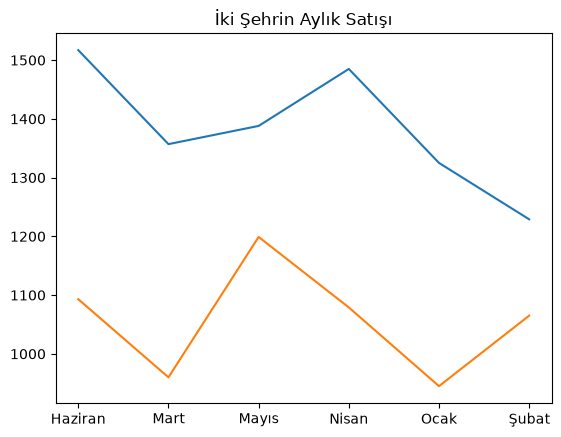

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

satis = pd.read_csv("../Data/05-coffee-sales.csv")

ist = satis[satis["sehir"] == "İstanbul"].groupby("ay")["adet"].sum()
ank = satis[satis["sehir"] == "Ankara"].groupby("ay")["adet"].sum()

plt.plot(ist.index, ist.values)
plt.plot(ank.index, ank.values)
plt.title("İki Şehrin Aylık Satışı")
plt.show()

**Gözlem:** İki çizgi çizildi ama hangisi İstanbul? Grafik cevap vermiyor; okuyucu tahmin yürütmek zorunda. Çözüm serileri **adlandırmak** ve göstergeyi (legend) eklemek:

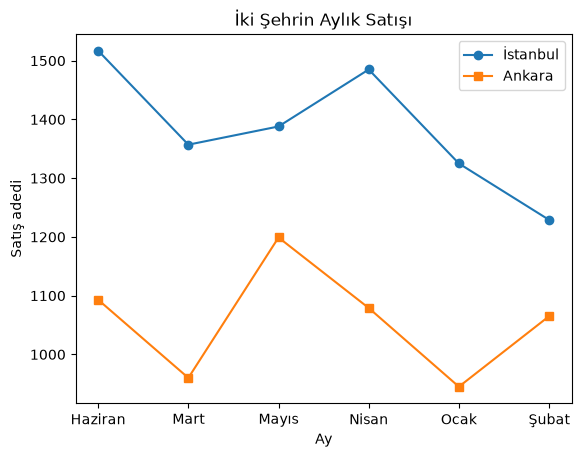

In [2]:
plt.plot(ist.index, ist.values, label="İstanbul", marker="o")
plt.plot(ank.index, ank.values, label="Ankara", marker="s")
plt.title("İki Şehrin Aylık Satışı")
plt.xlabel("Ay")
plt.ylabel("Satış adedi")
plt.legend()
plt.show()

**Gözlem:** `label` argümanı her seriyi adlandırıyor; `plt.legend()` bu adları grafiğin köşesine taşıyor. Artık soru okunuyor: iki şehir de büyüyor ama aradaki fark korunuyor. Çok serili grafikte `label` + `legend` ikilisi, tek seride başlık ve eksen etiketi kadar zorunludur.

## 📖 Kavramlar

**figure ve axes:** matplotlib'te **figure** (fig) tüm tuval, **axes** (ax) tuvaldeki tek grafik alanıdır. `plt.plot()` gizli bir "aktif axes" üzerinde çalışır; `fig, ax = plt.subplots()` ise tuvali ve alanı açıkça verir. Çoklu panelde bu açık yapı şarttır: her `ax` kendi `set_title`, `set_xlabel` komutlarını taşır.

**Gösterge (legend):** Seri adlarının grafik üzerindeki kutusu. `label` verilmeden `legend()` çağrılırsa gösterge boş kalır.

**Açıklama (annotate):** Grafiğin belirli bir noktasına ok ve metin yerleştirir. "Maksimum burada", "düşüş bu ayda başladı" gibi tekil mesajlar için idealdir.

**Eksen sınırları:** `xlim`/`ylim` görünen aralığı belirler. Güçlü bir araçtır; ama 1. dersten hatırla: çubuk grafikte dikey ekseni sıfırdan başlatmamak oranı çarpıtır. Sınır koymak bir tasarım kararıdır, keyfî değil.

**Stil (tema):** `plt.style.use("ggplot")` gibi tek satırla tüm görünümü (renk döngüsü, arka plan, ızgara, yazı) değiştirir. Dikkat: stil, çekirdek yeniden başlatılana kadar **kalıcıdır**; `plt.style.use("default")` ile geri dönersin.

## 🛠️ Uygulama

### 1) Çoklu panel: `subplots`

Dört ayrı soruyu tek figürde yanıtlayan bir pano kuralım. `axs` dizisi her panele erişir; 2 satır × 2 sütunlu yapıda `axs[0, 0]`, `axs[0, 1]`, `axs[1, 0]`, `axs[1, 1]`:

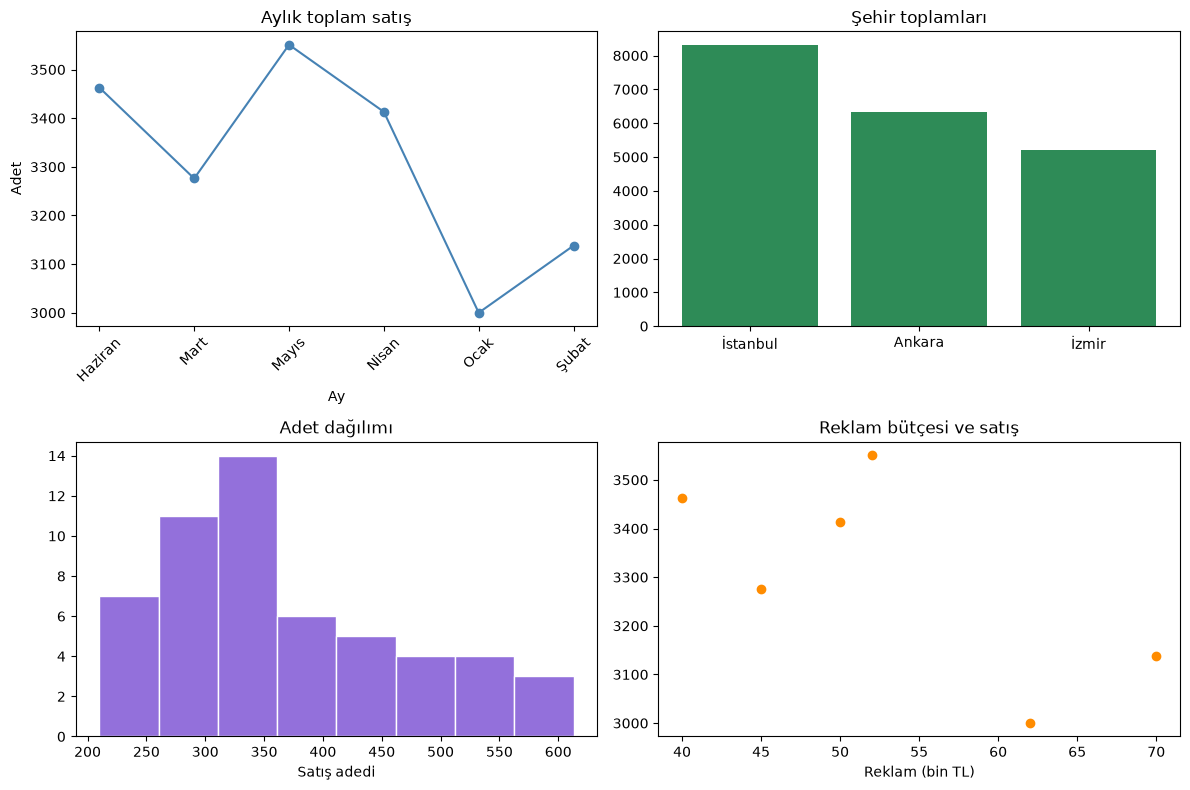

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Panel 1: aylık toplam (çizgi)
aylik = satis.groupby("ay")["adet"].sum()
axs[0, 0].plot(aylik.index, aylik.values, marker="o", color="steelblue")
axs[0, 0].set_title("Aylık toplam satış")
axs[0, 0].set_xlabel("Ay")
axs[0, 0].set_ylabel("Adet")
axs[0, 0].tick_params(axis="x", rotation=45)

# Panel 2: şehir toplamları (çubuk)
sehir = satis.groupby("sehir")["adet"].sum().sort_values(ascending=False)
axs[0, 1].bar(sehir.index, sehir.values, color="seagreen")
axs[0, 1].set_title("Şehir toplamları")

# Panel 3: adet dağılımı (histogram)
axs[1, 0].hist(satis["adet"], bins=8, color="mediumpurple", edgecolor="white")
axs[1, 0].set_title("Adet dağılımı")
axs[1, 0].set_xlabel("Satış adedi")

# Panel 4: reklam-satış ilişkisi (dağılım)
reklam = [40, 45, 52, 50, 62, 70]
axs[1, 1].scatter(reklam, aylik.values, color="darkorange")
axs[1, 1].set_title("Reklam bütçesi ve satış")
axs[1, 1].set_xlabel("Reklam (bin TL)")

plt.tight_layout()
plt.show()

Dikkat edilecek iki nokta: (1) panel komutları `plt.` değil `ax.` üzerinden: `set_title`, `set_xlabel`. (2) `plt.tight_layout()` panellerin birbirine girmesini önler; çoklu panelde neredeyse her zaman kullanılır.

### 2) annotate ile nokta vurgulama

Aylık toplam grafiğinde zirve ayı okla işaretleyelim:

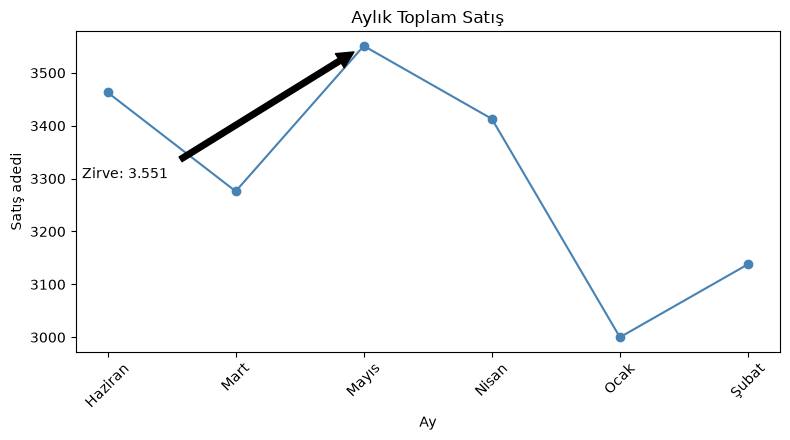

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.plot(aylik.index, aylik.values, marker="o", color="steelblue")
ax.set_title("Aylık Toplam Satış")
ax.set_xlabel("Ay")
ax.set_ylabel("Satış adedi")

en_buyuk = aylik.values.max()
en_buyuk_ay = aylik.values.argmax()
ax.annotate(f"Zirve: {en_buyuk:,}".replace(",", "."),
            xy=(en_buyuk_ay, en_buyuk),
            xytext=(en_buyuk_ay - 2.2, en_buyuk - 250),
            arrowprops=dict(facecolor="black", shrink=0.05))

ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

`xy` okun ucunun konumu (veri koordinatında), `xytext` metnin konumu, `arrowprops` okun görünümü. Vurgulamak istediğin mesaj tek bir noktaysa `annotate` idealdir; her noktayı etiketlemek ise 1. dersin "kalabalık grafik" hatasına gider.

### 3) Eksen sınırları: bilinçli kısma

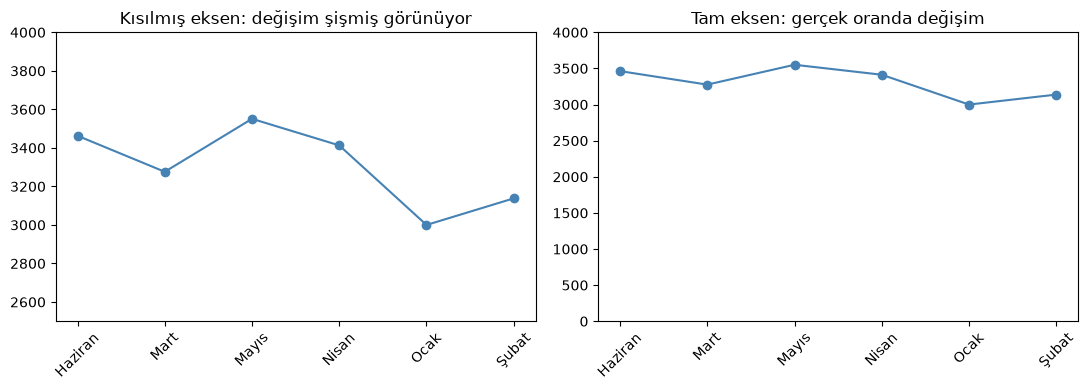

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(aylik.index, aylik.values, marker="o", color="steelblue")
ax1.set_ylim(2500, 4000)
ax1.set_title("Kısılmış eksen: değişim şişmiş görünüyor")

ax2.plot(aylik.index, aylik.values, marker="o", color="steelblue")
ax2.set_ylim(0, 4000)
ax2.set_title("Tam eksen: gerçek oranda değişim")

for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

Aynı veri, iki izlenim: solda değişim uçurum gibi, sağda sağlıklı büyüme. `ylim` güçlüdür ve güç, sorumluluk ister. Çizgi grafikte bağlam kazandırmak için makul bir alt sınır tartışılabilir; çubukta ise sıfır temel kuraldır (1. ders).

### 4) Kategorik renklerle çok serili grafik

Üç ürünün aylık seyrini, her ürün kendi renginde çizelim. Renk listesini biz veriyoruz; renk artık süs değil, ürün kimliği:

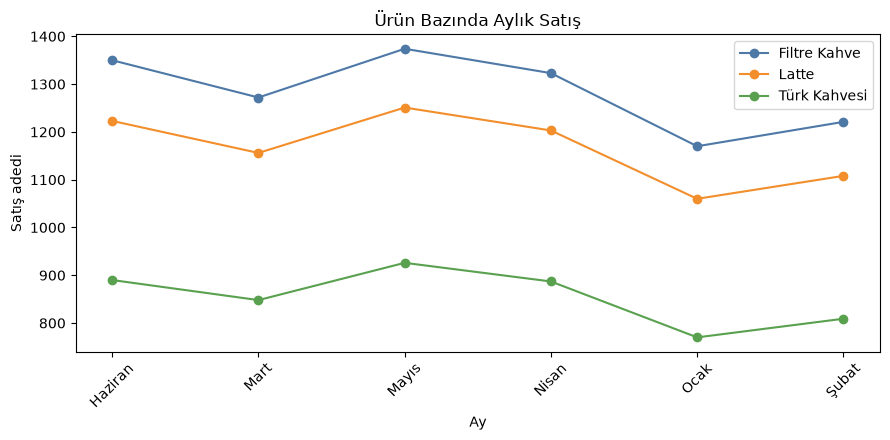

In [6]:
urun_renkleri = {
    "Filtre Kahve": "#4e79a7",
    "Latte": "#f28e2b",
    "Türk Kahvesi": "#59a14f",
}

fig, ax = plt.subplots(figsize=(9, 4.5))

for urun, renk in urun_renkleri.items():
    seri = satis[satis["urun"] == urun].groupby("ay")["adet"].sum()
    ax.plot(seri.index, seri.values, label=urun, color=renk, marker="o")

ax.set_title("Ürün Bazında Aylık Satış")
ax.set_xlabel("Ay")
ax.set_ylabel("Satış adedi")
ax.legend()
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

Ürün sırası ile renk sırası eşleşiyor ve gösterge bunu okuyucuya açıklıyor. Aynı renk dili raporun her grafiğinde aynı ürüne bağlanırsa, 1. dersin "tutarlılık" ilkesi yerine getirilmiş olur.

### 5) Hazır stiller

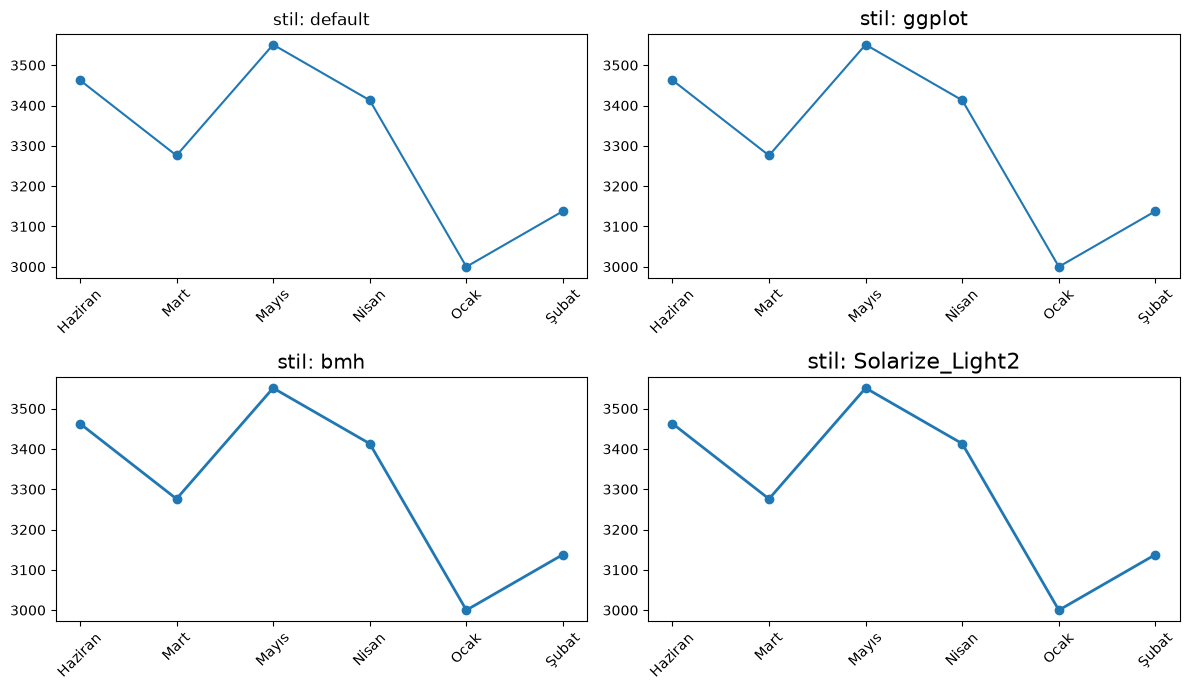

In [7]:
still = ["default", "ggplot", "bmh", "Solarize_Light2"]

fig, axs = plt.subplots(2, 2, figsize=(12, 7))

for ax, stil in zip(axs.flat, still):
    plt.style.use(stil)
    ax.plot(aylik.index, aylik.values, marker="o")
    ax.set_title(f"stil: {stil}")
    ax.tick_params(axis="x", rotation=45)

plt.style.use("default")
plt.tight_layout()
plt.show()

Aynı veri, dört kıyafet. Stil seçimi zevk meselesidir ama bir kere seçip rapor boyunca sabit tutmak profesyonelliğin işaretidir. Dikkat: hücrenin sonunda `plt.style.use("default")` ile geri döndük; yapmasaydık sonraki tüm hücreler son stille çizilirdi.

### 6) Grafiği dosyaya kaydetmek

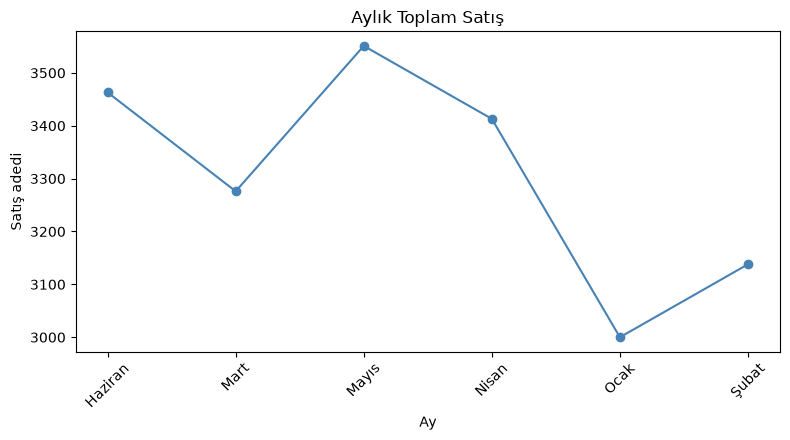

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(aylik.index, aylik.values, marker="o", color="steelblue")
ax.set_title("Aylık Toplam Satış")
ax.set_xlabel("Ay")
ax.set_ylabel("Satış adedi")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("aylik_satis.png", dpi=150, bbox_inches="tight")
plt.show()

`savefig` grafiği defterin yanına `aylik_satis.png` olarak yazdı. `dpi` çözünürlüğü (sunum için 150-300 arası iyi), `bbox_inches="tight"` kenar boşluklarını kırpar. **Önemli sıra:** `savefig` çağrısı `plt.show()`'dan önce gelmelidir; sonra çağrılırsa boş dosya kaydedebilir. PNG'nin yanı sıra `"grafik.pdf"` (belgeler için) ve `"grafik.svg"` (vektörel, ölçeklenebilir) uzantıları da kullanılabilir.

## 🧪 Deneyelim ve Gözlemleyelim

**Deney 1:** `label` verilmeden `legend()` çağırırsan ne olur? Tahmin et, sonra aşağıdaki hücreyi çalıştır ve çıktıdaki uyarıyı oku:

/tmp/ipykernel_202196/3608395921.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


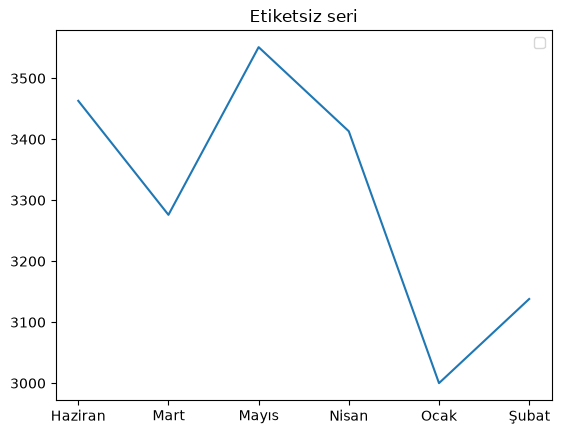

In [9]:
plt.plot(aylik.index, aylik.values)
plt.title("Etiketsiz seri")
plt.legend()
plt.show()

**Gözlem:** Grafik çizildi ama gösterge boş ve çıktıda bir uyarı belirdi: matplotlib, adlandırılmış seri bulamadığını söylüyor. `label` olmadan `legend` anlamsızdır — sessiz değil ama kolay gözden kaçan bir hata.

**Deney 2:** `annotate`'ın `xytext` değerini değiştirerek okun yönünü taşı: örneğin `xytext=(en_buyuk_ay - 2.2, en_buyuk - 250)` yerine `(0.5, en_buyuk + 150)` dene. Metin kutusunun grafiğin neresine gittiğini gözlemle; metin verinin üstüne binmesin diye değerlerle oynamak annotate'ın günlük işidir.

**Deney 3:** `tight_layout()` olmadan çoklu panel çiz. Panellerin başlıkları ve eksen etiketleri ne yapıyor? (Yukarıdaki pano kodundan `plt.tight_layout()` satırını çıkarıp yeniden çalıştır.)

## 🧯 Bir Şeyler Ters Giderse

| Belirti | Olası neden | Çözüm |
|---|---|---|
| `TypeError: 'AxesSubplot' object is not subscriptable` | Tek satırlı `subplots(1, 2)`'de `axs[0, 1]` gibi iki indeks kullanıldı | Tek boyutlu dizide `axs[0]`, `axs[1]`; iki boyutluda `axs[0, 1]` |
| `legend()` boş görünüyor + uyarı | Serilere `label` verilmemiş | Her `plot`/`bar` çağrısına `label="..."` ekle |
| Sonraki grafikler garip görünüyor | `plt.style.use` kalıcı etki etti | `plt.style.use("default")` ya da çekirdeği yeniden başlat |
| `savefig` boş/beyaz dosya üretti | `show()`'dan sonra çağrıldı | `savefig`'i `show()`'dan önce çalıştır |
| Paneller üst üste biniyor | Yerleşim optimize edilmemiş | `plt.tight_layout()` ekle |
| `ValueError: x and y must have same first dimension` | Panelde karışan veri uzunlukları | Her panel için kendi grubunu hazırla; `len(...)` ile kontrol et |

> **İpucu:** Çoklu panelde en sık yapılan hata paneller arasında veri karıştırmaktır. Her panelin verisini tek bir hücrede, açık adlarla hazırla (`ist_aylik`, `urun_toplam` gibi); kopyala-yapıştır panellerinde adları güncellemeyi unutma.

## 🏋️ Kendin Dene

Kahve tablosu için **"Zincir Sağlık Panosu"** hazırla: 2×2 panellik bir figür, tutarlı bir stil, ve en az bir `annotate`:

1. Panel (sol üst): İzmir'in aylık satış çizgisi; zirve ayı `annotate` ile işaretli.
2. Panel (sağ üst): Ürün toplamları yatay çubuklarla.
3. Panel (sol alt): `haftalik_kahve` değil — bu tabloda `adet` histogramı (bins=10).
4. Panel (sağ alt): Şehir × ürün kırılımında toplam adetleri gösteren gruplu çubuk (her ürün bir renk, `legend` ile).

Sonra panoyu `saglik_panosu.png` olarak kaydet.


## 🧠 Öğrendiklerini Kontrol Et

Cevaplar defterin sonundaki "Cevaplar" bölümünde. Önce kendin dene.

1. `plt.subplots(2, 2)` çağrısının döndürdüğü iki nesne nedir, ne işe yarar?
2. Çok serili bir grafikte okuyucunun "hangi çizgi hangi seri?" sorusunu iki araçla yanıtlarsın. Hangileri?
3. `ax.set_title(...)` ile `plt.title(...)` arasındaki fark nedir? Hangi durumda `plt.title` işe yaramaz?
4. `plt.style.use("ggplot")` çalıştırdıktan sonra not aldın, defteri kapatıp ertesi gün yeni bir grafik çizdin. Yeni grafik hangi stille çizilir?
5. `annotate`'ın `xy` ve `xytext` parametreleri arasındaki fark nedir?
6. `savefig`'in `dpi` ve `bbox_inches` parametreleri neyi kontrol eder; `savefig` hangi komutla aynı hücrede ve hangi sırada kullanılmalı?

## 🚀 Bağımsız Çalışma

- **Stil kataloğu:** `plt.style.available` komutu tüm stil adlarını listeler. Beşini seçip aynı grafiği beş kez, her seferinde başka stille çiz. Kendi "imza stilini" seç ve 15-16. derslerde kullanmak üzere not et.
- **Belge kalitesi:** Aynı grafiği üç formatta kaydet: PNG (dpi=72), PNG (dpi=300) ve SVG. Dosya boyutlarına bak; hangisi sunuma, hangisi yazdırılan belgeye uyar?

## 📚 Daha Fazlasını Öğrenmek

- Matplotlib stil galerisi: https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html
- Matplotlib eğitimleri: https://matplotlib.org/stable/tutorials/index.html

İngilizcedir; örnekler doğrudan çalıştırılabilir.

## ✅ Kısa Özet

- `fig, axs = plt.subplots(satır, sütun)` çoklu pano kurar; panel komutları `ax.` üzerinden yürür (`set_title`, `set_xlabel`).
- Çok serili grafikte `label` + `legend` zorunludur; `label`'sız `legend` boş kalır ve uyarı verir.
- `annotate` tekil mesaj noktalarını okla işaretler; `xy` okun ucu, `xytext` metnin yeri.
- `xlim`/`ylim` güçlüdür: çubukta sıfır tabanı, çizgide dürüst aralık esastır.
- `plt.style.use` tüm görünümü değiştirir ve kalıcıdır; `default` ile geri dönülür.
- `savefig` grafiği dosyaya yazar; `show()`'dan önce, `dpi` ve `bbox_inches="tight"` ile çağrılır.

Sıradaki derste aynı grafikleri daha az kodla üreteceğimiz yüksek seviyeli bir arayüze geçiyoruz: seaborn.

---

[← Önceki ders: Matplotlib Temelleri](07-Matplotlib-Basics.ipynb) · [Sıradaki ders: Seaborn Temelleri →](09-Seaborn-Basics.ipynb)

## Cevaplar

### Kontrol Et 1

`fig` (figure: tüm tuval) ve `axs` (axes: panel dizisi). Tuvalin boyutunu ve genel yerleşimi fig belirler; her panelin kendi çizim ve etiket komutları ilgili `ax` üzerinden verilir.

### Kontrol Et 2

`label` argümanı (seriyi adlandırır) ve `legend()` (adları görünen gösterge kutusuna taşır). İkisi birlikte çalışır.

### Kontrol Et 3

`plt.title` gizli "aktif axes"e yazılır; çoklu panelde hangi panelin aktif olduğu belirsizleşir. `ax.set_title` hedef paneli açıkça belirtir. Çoklu panelde `plt.title` ya yanlış panele yazar ya hiç yazmaz; bu yüzden `ax.` komutları kullanılır.

### Kontrol Et 4

`ggplot` ile. Stil seçimi kalıcıdır: defter kapatılsa bile kayıtlı hücreler ve çekirdek durumu yeniden yüklendiğinde stil ayarı da geri gelir. Yeni defterde değil ama aynı çekirdekte kesinlikle sürer; güvenli davranış her stil denemesinden sonra `default`'a dönmektir.

### Kontrol Et 5

`xy` okun ucunun grafiğe değdiği nokta (genellikle veri noktasının kendisi); `xytext` açıklama metninin yerleştirildiği nokta. İkisi arasına ok çizilir.

### Kontrol Et 6

`dpi` çözünürlüğü (inç başına nokta sayısı; büyük değer = keskin ama büyük dosya), `bbox_inches="tight"` grafiği çevreleyen boşluğu kırpar. `savefig` aynı hücrede `plt.show()`'dan önce çağrılmalıdır.

### İpuçları

**Kendin Dene:** Panel 4 için her ürünü ayrı bir `bar` ile çizebilirsin: x ekseninde şehirler, her şehirde yan yana üç çubuk (gruplu çubuk için `x + genislik/2` ofsetlerini 2. dersteki gruplu çubuk örneğinden hatırla). Renkleri `urun_renkleri` sözlüğünden al; tutarlılık bunu gerektirir.
